# Monarchs and Glens — Route Analysis

This notebook explores the *Monarchs and Glens* GPX route: a multi-day trail running race through the Angus Glens and Cairngorms.
The GPX contains the full track plus 10 checkpoint waypoints that divide the route into legs.

In [1]:
import math
import gpxpy
import gpxpy.geo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

## 1. Parse the GPX file

In [2]:
GPX_FILE = "../Monarchs and Glens.gpx"

with open(GPX_FILE) as f:
    gpx = gpxpy.parse(f)

# ── Waypoints (checkpoints) ──────────────────────────────────────────────────
waypoints = [
    {'name': w.name, 'desc': w.description or '', 'lat': w.latitude, 'lon': w.longitude}
    for w in gpx.waypoints
]

# ── Track points ─────────────────────────────────────────────────────────────
points = gpx.tracks[0].segments[0].points
lats = np.array([p.latitude  for p in points])
lons = np.array([p.longitude for p in points])
eles = np.array([p.elevation for p in points])

# Cumulative distance using gpxpy's haversine
seg_dist = np.zeros(len(points))
for i in range(1, len(points)):
    seg_dist[i] = gpxpy.geo.haversine_distance(lats[i-1], lons[i-1], lats[i], lons[i])
cum_dist_km = np.cumsum(seg_dist) / 1000

# Overall ascent/descent from gpxpy
uphill, downhill = gpx.get_uphill_downhill()
total_dist_km = cum_dist_km[-1]

print(f"Waypoints      : {len(waypoints)}")
print(f"Track points   : {len(points)}")
print(f"Total distance : {total_dist_km:.1f} km")
print(f"Total ascent   : {uphill:.0f} m")
print(f"Total descent  : {downhill:.0f} m")
print(f"Start elevation: {eles[0]:.0f} m")
print(f"Max elevation  : {eles.max():.0f} m")
print(f"Min elevation  : {eles.min():.0f} m")

Waypoints      : 10
Track points   : 2834
Total distance : 123.1 km
Total ascent   : 3433 m
Total descent  : 3643 m
Start elevation: 413 m
Max elevation  : 1017 m
Min elevation  : 202 m


## 2. Assign each checkpoint to the nearest track point

We snap each waypoint to its closest track point, then use those indices to split the route into legs.

In [3]:
def nearest_track_idx(wpt_lat, wpt_lon, lats, lons):
    """Return index of the track point closest to (wpt_lat, wpt_lon)."""
    dlat = np.radians(lats - wpt_lat)
    dlon = np.radians(lons - wpt_lon)
    phi1 = math.radians(wpt_lat)
    phis = np.radians(lats)
    a = np.sin(dlat/2)**2 + np.cos(phi1)*np.cos(phis)*np.sin(dlon/2)**2
    return int(np.argmin(a))

for wpt in waypoints:
    idx = nearest_track_idx(wpt['lat'], wpt['lon'], lats, lons)
    wpt['track_idx']  = idx
    wpt['dist_km']    = cum_dist_km[idx]
    wpt['ele_m']      = eles[idx]
    wpt['snap_err_m'] = gpxpy.geo.haversine_distance(
        wpt['lat'], wpt['lon'], lats[idx], lons[idx]
    )

waypoints.sort(key=lambda w: w['track_idx'])

# Add start and finish as explicit checkpoints
def make_endpoint(name, idx):
    return {'name': name, 'desc': '', 'lat': lats[idx], 'lon': lons[idx],
            'track_idx': idx, 'dist_km': cum_dist_km[idx], 'ele_m': eles[idx], 'snap_err_m': 0.0}

waypoints = [make_endpoint('Start', 0)] + waypoints + [make_endpoint('Finish', len(points) - 1)]

cp_df = pd.DataFrame(waypoints)[['name', 'dist_km', 'ele_m', 'snap_err_m']]
cp_df.columns = ['Checkpoint', 'Distance (km)', 'Elevation (m)', 'Snap error (m)']
cp_df.index = range(len(cp_df))
cp_df.style.format({'Distance (km)': '{:.1f}', 'Elevation (m)': '{:.0f}', 'Snap error (m)': '{:.0f}'})

,Checkpoint,Distance (km),Elevation (m),Snap error (m)
0,Start,0.0,413,0
1,Glen Doll Rangers Station,10.7,264,0
2,Glen Prosen Lodge,24.0,315,0
3,Glen Head Farm,33.7,323,0
4,Freuchies,42.0,262,0
5,Auchavan,56.1,367,0
6,A93,69.2,523,0
7,Auchallater,83.5,374,0
8,Old Invercauld Bridge,94.4,323,0
9,Easter Balmoral,105.7,287,0


## 3. Leg summary table

In [4]:
# Legs run between consecutive waypoints (now including Start and Finish)
legs = []
for k in range(len(waypoints) - 1):
    w0, w1 = waypoints[k], waypoints[k + 1]
    i0, i1 = w0['track_idx'], w1['track_idx']
    e_seg   = eles[i0:i1+1]
    d_diff  = np.diff(e_seg)
    legs.append({
        'Leg': k + 1,
        'Name': f"{w0['name']} → {w1['name']}",
        'Distance (km)': cum_dist_km[i1] - cum_dist_km[i0],
        'Ascent (m)':    d_diff[d_diff > 0].sum(),
        'Descent (m)':  -d_diff[d_diff < 0].sum(),
        'Start elev (m)': eles[i0],
        'End elev (m)':   eles[i1],
        'i0': i0, 'i1': i1,
    })

legs_df = pd.DataFrame(legs)

display_cols = ['Leg', 'Name', 'Distance (km)', 'Ascent (m)', 'Descent (m)', 'Start elev (m)', 'End elev (m)']
legs_df[display_cols].style.format({
    'Distance (km)': '{:.1f}',
    'Ascent (m)': '{:.0f}',
    'Descent (m)': '{:.0f}',
    'Start elev (m)': '{:.0f}',
    'End elev (m)': '{:.0f}',
}).set_caption('Leg summary')

,Leg,Name,Distance (km),Ascent (m),Descent (m),Start elev (m),End elev (m)
0,1,Start → Glen Doll Rangers Station,10.7,387,535,413,264
1,2,Glen Doll Rangers Station → Glen Prosen Lodge,13.3,611,561,264,315
2,3,Glen Prosen Lodge → Glen Head Farm,9.7,313,306,315,323
3,4,Glen Head Farm → Freuchies,8.3,131,191,323,262
4,5,Freuchies → Auchavan,14.1,332,228,262,367
5,6,Auchavan → A93,13.1,686,531,367,523
6,7,A93 → Auchallater,14.2,564,713,523,374
7,8,Auchallater → Old Invercauld Bridge,11.0,166,216,374,323
8,9,Old Invercauld Bridge → Easter Balmoral,11.2,132,168,323,287
9,10,Easter Balmoral → Littlemill,11.4,190,238,287,239


## 4. Full elevation profile

In [5]:
plt.style.use('kentigern-light')

/tmp/ipykernel_25150/1527967310.py:27: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


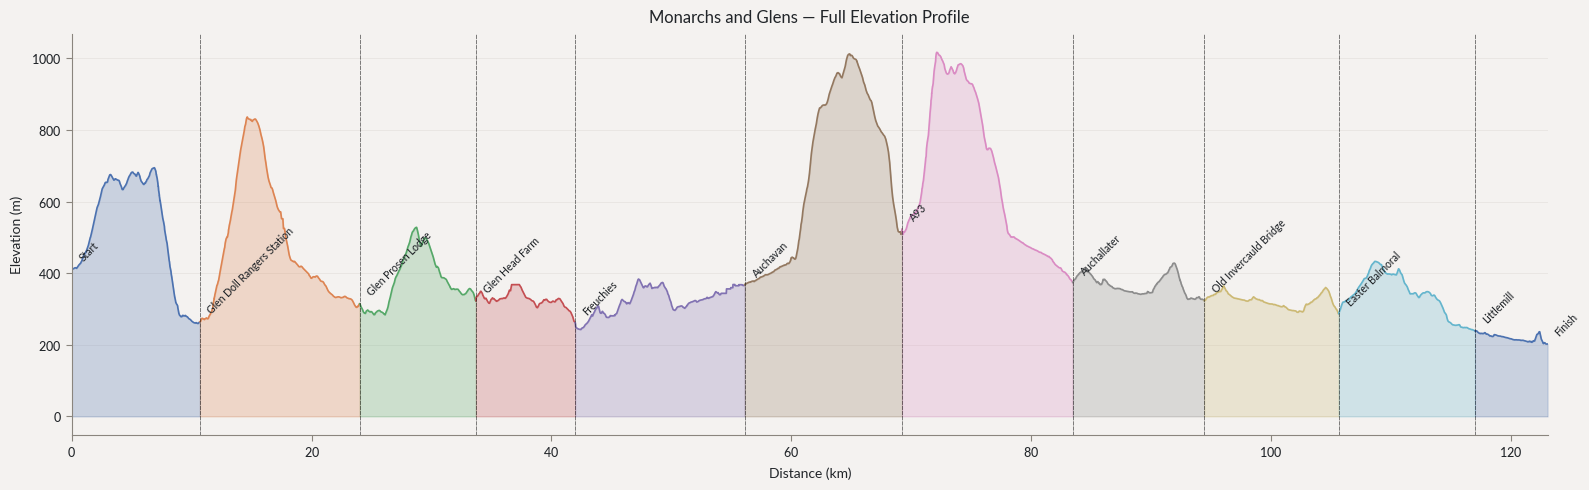

In [6]:
# Colour legs alternately so they're easy to distinguish
LEG_COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2',
               '#937860', '#DA8BC3', '#8C8C8C', '#CCB974', '#64B5CD',
               '#4C72B0', '#DD8452']

fig, ax = plt.subplots(figsize=(16, 5))

for k, leg in legs_df.iterrows():
    i0, i1 = int(leg['i0']), int(leg['i1'])
    ax.fill_between(cum_dist_km[i0:i1+1], eles[i0:i1+1],
                    alpha=0.25, color=LEG_COLORS[k % len(LEG_COLORS)])
    ax.plot(cum_dist_km[i0:i1+1], eles[i0:i1+1],
            color=LEG_COLORS[k % len(LEG_COLORS)], lw=1.2)

# Checkpoint markers
for wpt in waypoints:
    ax.axvline(wpt['dist_km'], color='black', lw=0.7, ls='--', alpha=0.5)
    ax.annotate(wpt['name'], xy=(wpt['dist_km'], wpt['ele_m']),
                xytext=(4, 4), textcoords='offset points',
                fontsize=7.5, rotation=45, va='bottom')

ax.set_xlabel('Distance (km)')
ax.set_ylabel('Elevation (m)')
ax.set_title('Monarchs and Glens — Full Elevation Profile')
ax.set_xlim(0, cum_dist_km[-1])
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Individual leg elevation profiles

/tmp/ipykernel_25150/3340558933.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


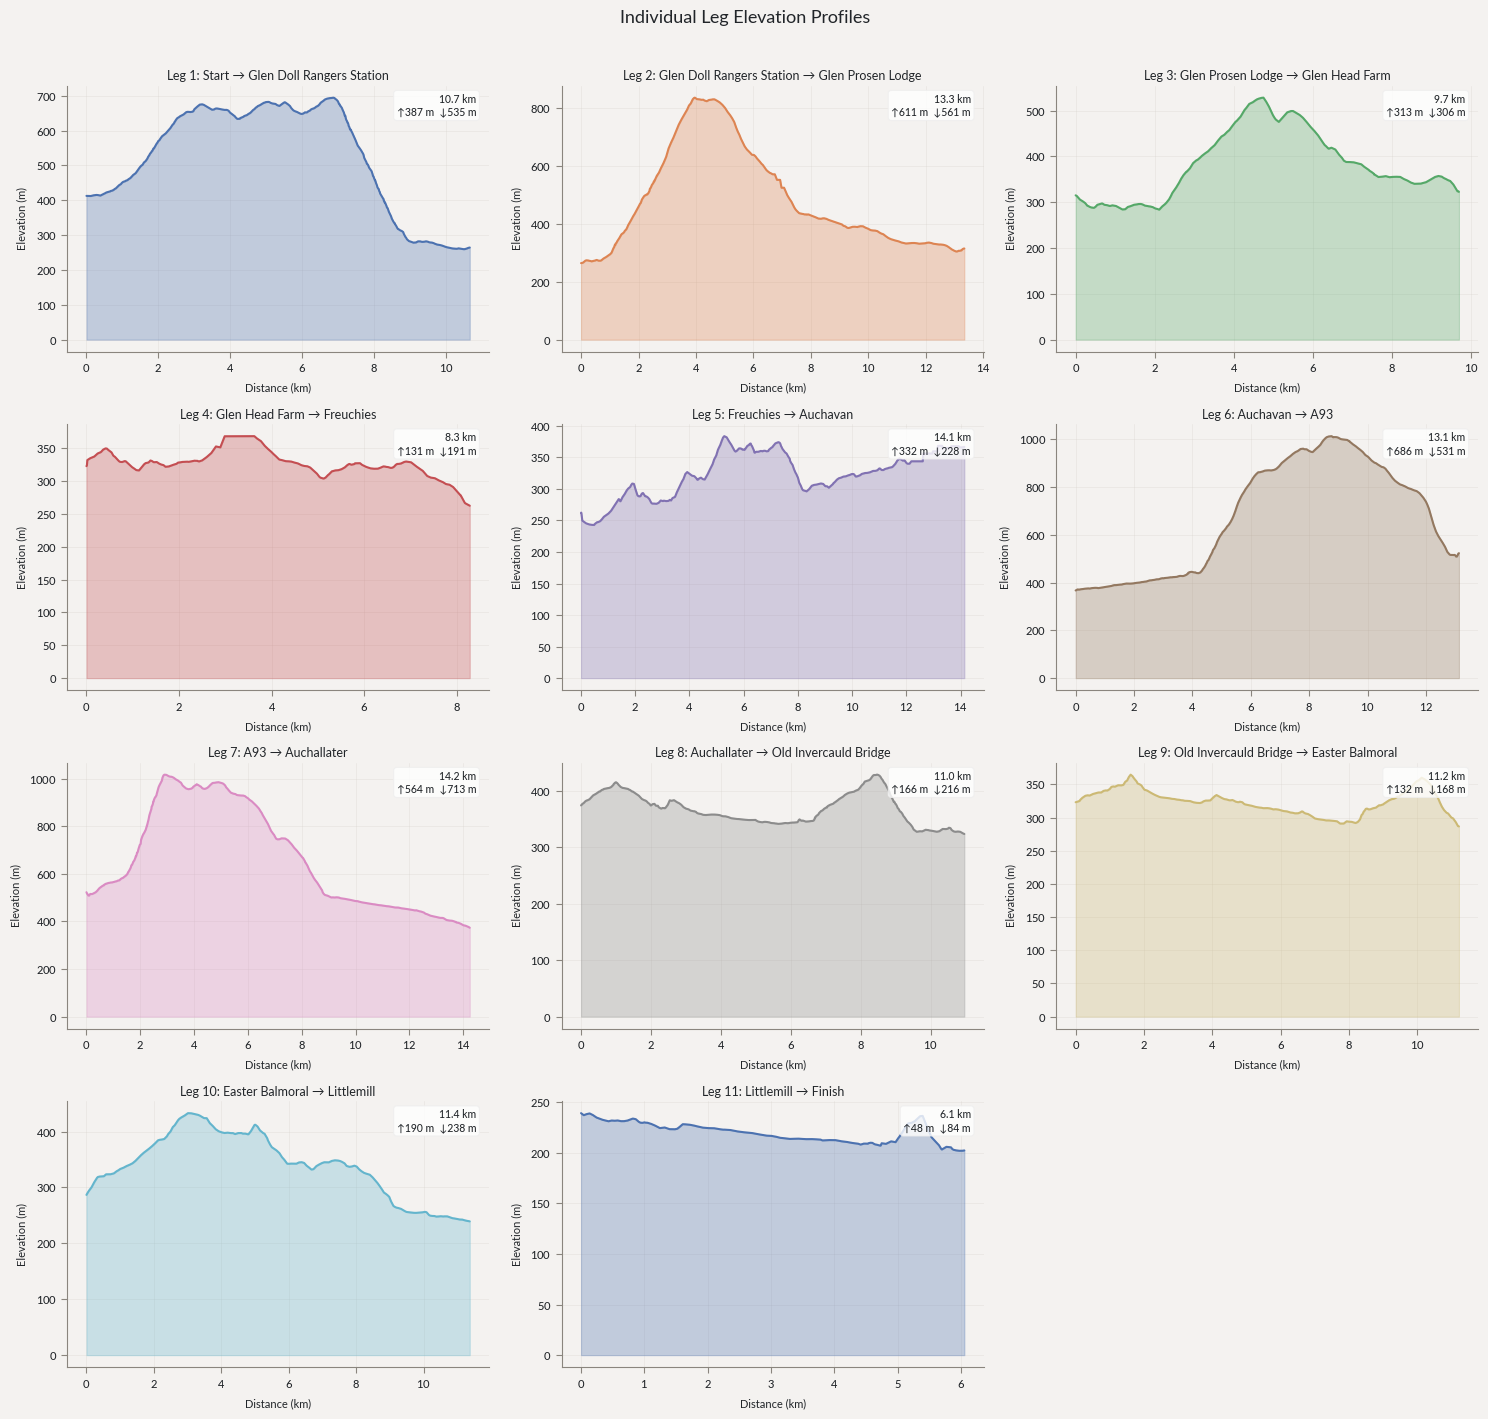

In [7]:
n_legs = len(legs_df)
ncols  = 3
nrows  = math.ceil(n_legs / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.5*nrows))
axes = axes.flatten()

for k, leg in legs_df.iterrows():
    ax = axes[k]
    i0, i1 = int(leg['i0']), int(leg['i1'])
    d  = cum_dist_km[i0:i1+1] - cum_dist_km[i0]   # relative distance
    e  = eles[i0:i1+1]
    color = LEG_COLORS[k % len(LEG_COLORS)]

    ax.fill_between(d, e, alpha=0.3, color=color)
    ax.plot(d, e, color=color, lw=1.5)

    ax.set_title(f"Leg {k+1}: {leg['Name']}", fontsize=9, pad=4)
    ax.set_xlabel('Distance (km)', fontsize=8)
    ax.set_ylabel('Elevation (m)', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.35)

    # Small stats box
    stats = (f"{leg['Distance (km)']:.1f} km\n"
             f"↑{leg['Ascent (m)']:.0f} m  ↓{leg['Descent (m)']:.0f} m")
    ax.text(0.97, 0.97, stats, transform=ax.transAxes,
            va='top', ha='right', fontsize=7.5,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8))

# Hide unused subplots
for j in range(n_legs, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Individual Leg Elevation Profiles', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 6. Leg comparison — distance and ascent

/tmp/ipykernel_25150/1777767113.py:26: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


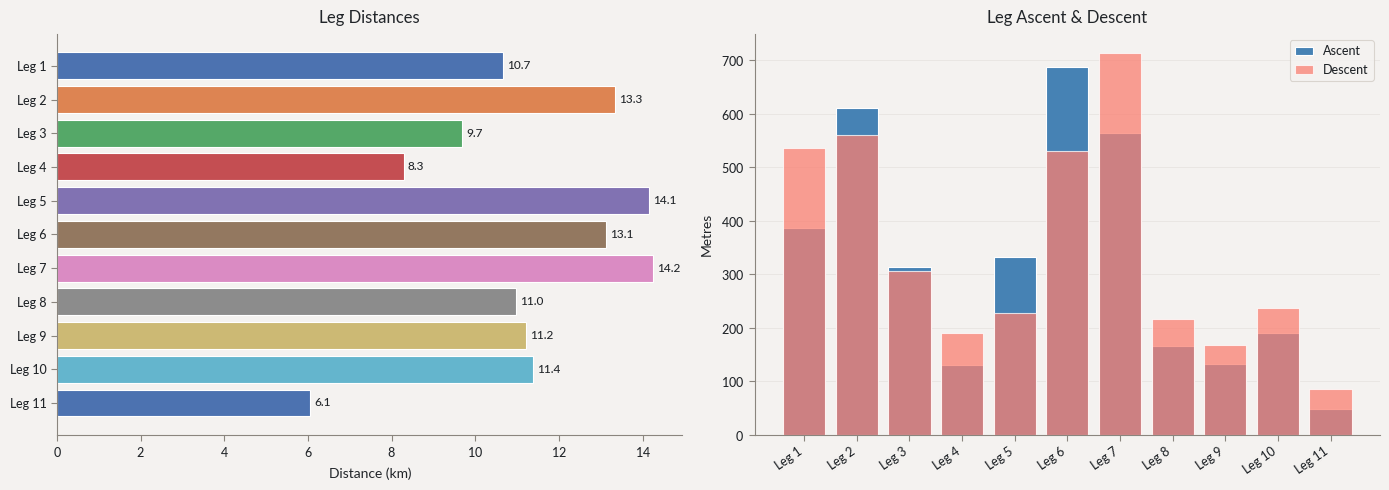

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

leg_labels = [f"Leg {r['Leg']}" for _, r in legs_df.iterrows()]
colors     = [LEG_COLORS[i % len(LEG_COLORS)] for i in range(n_legs)]

# Distance
ax1.barh(leg_labels, legs_df['Distance (km)'], color=colors, edgecolor='white')
for i, v in enumerate(legs_df['Distance (km)']):
    ax1.text(v + 0.1, i, f'{v:.1f}', va='center', fontsize=8.5)
ax1.set_xlabel('Distance (km)')
ax1.set_title('Leg Distances')
ax1.invert_yaxis()

# Stacked ascent + descent
x_pos = range(n_legs)
ax2.bar(x_pos, legs_df['Ascent (m)'],  label='Ascent',  color='steelblue', edgecolor='white')
ax2.bar(x_pos, legs_df['Descent (m)'], label='Descent', color='salmon',    edgecolor='white',
        alpha=0.75, bottom=0)
ax2.set_xticks(list(x_pos))
ax2.set_xticklabels(leg_labels, rotation=35, ha='right')
ax2.set_ylabel('Metres')
ax2.set_title('Leg Ascent & Descent')
ax2.legend()
ax2.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

## 7. Gradient profile

Gradient (%) computed over a rolling 500 m window to smooth out GPS noise.

/tmp/ipykernel_25150/1302748436.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


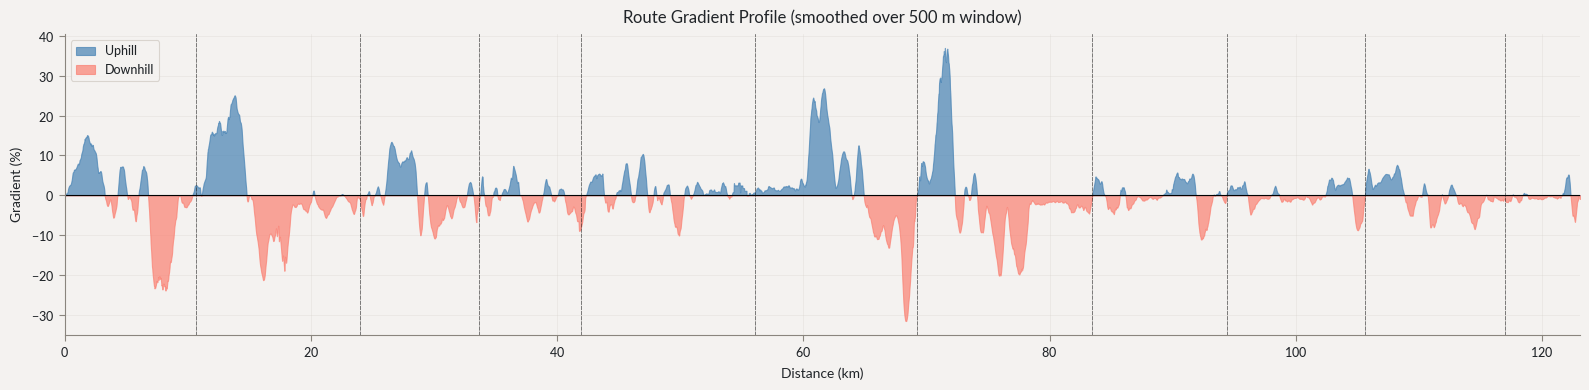

In [9]:
# Rolling gradient over ~500 m window
WINDOW_KM = 0.5

# Resample to regular 10 m spacing for clean smoothing
d_uniform = np.arange(0, cum_dist_km[-1], 0.01)          # every 10 m
e_uniform = np.interp(d_uniform, cum_dist_km, eles)

window_pts = max(int(WINDOW_KM / 0.01), 2)
e_smooth   = pd.Series(e_uniform).rolling(window_pts, center=True, min_periods=1).mean().values

grad = np.gradient(e_smooth, d_uniform * 1000) * 100      # % gradient

fig, ax = plt.subplots(figsize=(16, 4))

pos_grad = np.where(grad > 0, grad, 0)
neg_grad = np.where(grad < 0, grad, 0)

ax.fill_between(d_uniform, pos_grad, color='steelblue', alpha=0.7, label='Uphill')
ax.fill_between(d_uniform, neg_grad, color='salmon',    alpha=0.7, label='Downhill')
ax.axhline(0, color='black', lw=0.8)

for wpt in waypoints:
    ax.axvline(wpt['dist_km'], color='black', lw=0.7, ls='--', alpha=0.5)

ax.set_xlabel('Distance (km)')
ax.set_ylabel('Gradient (%)')
ax.set_title(f'Route Gradient Profile (smoothed over {WINDOW_KM*1000:.0f} m window)')
ax.set_xlim(0, cum_dist_km[-1])
ax.legend()
ax.grid(alpha=0.35)
plt.tight_layout()
plt.show()

## 8. Elevation distribution by leg

How much of each leg is spent at what altitude? Horizontal box plots give a quick overview.

/tmp/ipykernel_25150/460884391.py:15: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


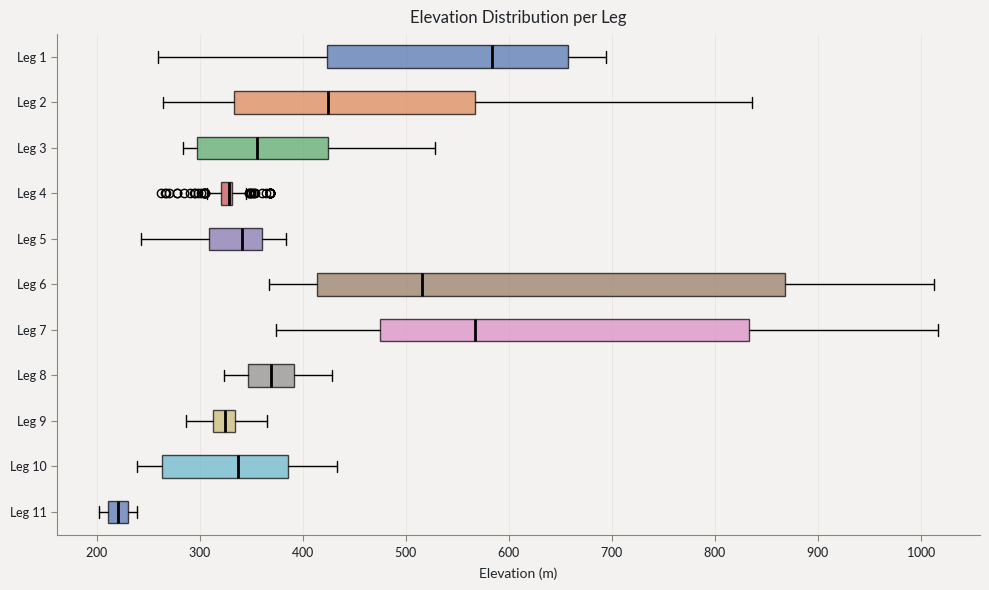

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

leg_eles   = [eles[int(r['i0']):int(r['i1'])+1] for _, r in legs_df.iterrows()]
bp = ax.boxplot(leg_eles[::-1], vert=False, patch_artist=True,
                medianprops=dict(color='black', lw=2))

for patch, color in zip(bp['boxes'], [LEG_COLORS[i % len(LEG_COLORS)] for i in range(n_legs-1,-1,-1)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_yticklabels([f"Leg {r['Leg']}" for _, r in legs_df.iterrows()][::-1])
ax.set_xlabel('Elevation (m)')
ax.set_title('Elevation Distribution per Leg')
ax.grid(axis='x', alpha=0.4)
plt.tight_layout()
plt.show()

## 9. Route hypsometry — distance above each elevation band

/tmp/ipykernel_25150/428373639.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


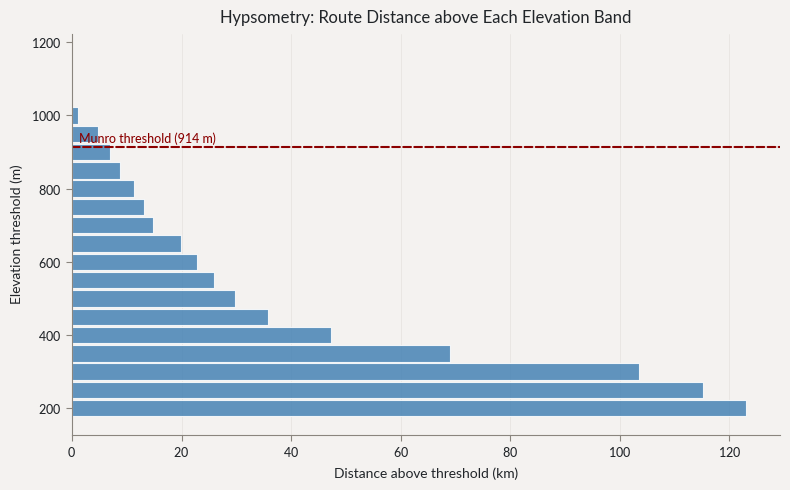

In [11]:
thresholds = np.arange(200, 1200, 50)

# Fraction of track distance above each threshold (use uniform resampling)
dist_above = []
total_d = d_uniform[-1]
for t in thresholds:
    frac = np.mean(e_uniform >= t)
    dist_above.append(frac * total_d)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(thresholds, dist_above, height=45, color='steelblue', edgecolor='white', alpha=0.85)
ax.set_xlabel('Distance above threshold (km)')
ax.set_ylabel('Elevation threshold (m)')
ax.set_title('Hypsometry: Route Distance above Each Elevation Band')
ax.grid(axis='x', alpha=0.4)

# Annotate Munro threshold
ax.axhline(914, color='darkred', lw=1.5, ls='--')
ax.text(ax.get_xlim()[1]*0.01, 918, 'Munro threshold (914 m)', color='darkred', fontsize=9, va='bottom')

plt.tight_layout()
plt.show()

## 10. Headline stats summary

In [12]:
n_above_munro = np.mean(e_uniform >= 914) * total_d

stats_data = {
    'Metric': [
        'Total distance',
        'Total ascent',
        'Total descent',
        'Start elevation',
        'Highest point',
        'Lowest point',
        'Distance above Munro threshold (914 m)',
        'Number of checkpoints',
        'Number of legs',
    ],
    'Value': [
        f'{total_dist_km:.1f} km',
        f'{uphill:.0f} m',
        f'{downhill:.0f} m',
        f'{eles[0]:.0f} m',
        f'{eles.max():.0f} m',
        f'{eles.min():.0f} m',
        f'{n_above_munro:.1f} km  ({100*n_above_munro/total_d:.1f}%)',
        f'{len(waypoints)}',
        f'{len(legs_df)}',
    ],
}

pd.DataFrame(stats_data)

,Metric,Value
0,Total distance,123.1 km
1,Total ascent,3433 m
2,Total descent,3643 m
3,Start elevation,413 m
4,Highest point,1017 m
5,Lowest point,202 m
6,Distance above Munro threshold (914 m),6.4 km (5.2%)
7,Number of checkpoints,12
8,Number of legs,11


## 11. Naismith time estimates

Naismith's rule gives a rough time estimate: 5 km/h on flat ground, plus 1 hour for every 600 m of ascent. The bars show per-leg time; the line shows cumulative elapsed time from the start.

,Leg,Name,Distance (km),Ascent (m),Time,Cumul. time
0,1,Start → Glen Doll Rangers Station,10.7,387,2:47,2:47
1,2,Glen Doll Rangers Station → Glen Prosen Lodge,13.3,611,3:41,6:28
2,3,Glen Prosen Lodge → Glen Head Farm,9.7,313,2:28,8:55
3,4,Glen Head Farm → Freuchies,8.3,131,1:52,10:48
4,5,Freuchies → Auchavan,14.1,332,3:23,14:11
5,6,Auchavan → A93,13.1,686,3:46,17:57
6,7,A93 → Auchallater,14.2,564,3:47,21:44
7,8,Auchallater → Old Invercauld Bridge,11.0,166,2:28,24:12
8,9,Old Invercauld Bridge → Easter Balmoral,11.2,132,2:28,26:40
9,10,Easter Balmoral → Littlemill,11.4,190,2:35,29:16


/tmp/ipykernel_25150/4028490303.py:39: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


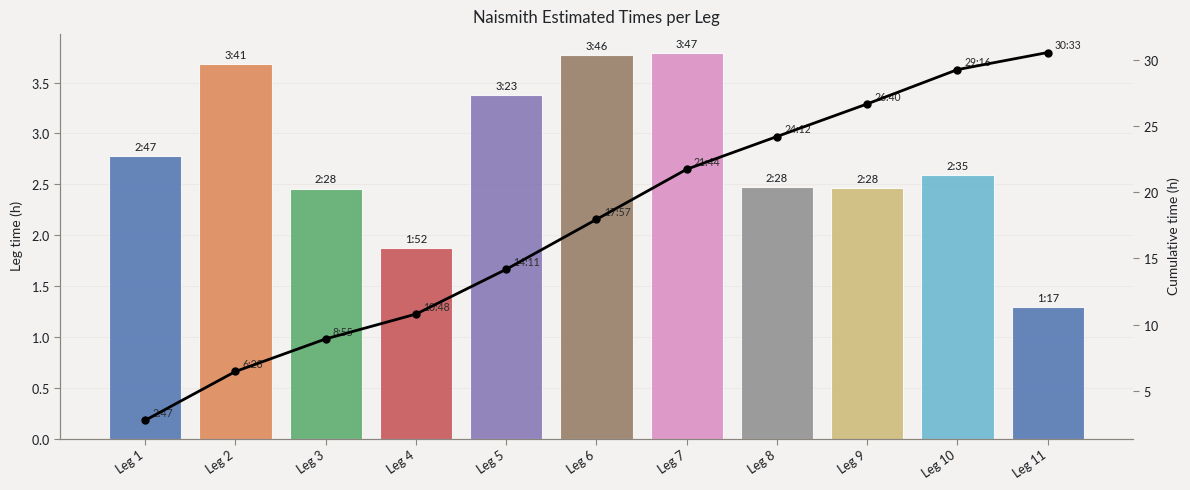

In [13]:
FLAT_SPEED_KMH = 5.0        # Naismith: 5 km/h on flat
ASCENT_H_PER_M = 1 / 600   # Naismith: +1 h per 600 m ascent

legs_df['Naismith (h)']   = legs_df['Distance (km)'] / FLAT_SPEED_KMH + legs_df['Ascent (m)'] * ASCENT_H_PER_M
legs_df['Cumul. time (h)'] = legs_df['Naismith (h)'].cumsum()

def fmt_hm(h):
    total_min = round(h * 60)
    hh, mm = divmod(total_min, 60)
    return f'{hh}:{mm:02d}'

legs_df['Time']        = legs_df['Naismith (h)'].map(fmt_hm)
legs_df['Cumul. time'] = legs_df['Cumul. time (h)'].map(fmt_hm)

display(legs_df[['Leg', 'Name', 'Distance (km)', 'Ascent (m)', 'Time', 'Cumul. time']].style
        .format({'Distance (km)': '{:.1f}', 'Ascent (m)': '{:.0f}'})
        .set_caption(f'Naismith estimated times ({FLAT_SPEED_KMH:.0f} km/h flat, 1 h per 600 m ascent)'))

fig, ax = plt.subplots(figsize=(12, 5))
ax2 = ax.twinx()
x = range(n_legs)
colors = [LEG_COLORS[i % len(LEG_COLORS)] for i in range(n_legs)]
leg_labels = ['Leg ' + str(int(r['Leg'])) for _, r in legs_df.iterrows()]

ax.bar(x, legs_df['Naismith (h)'], color=colors, edgecolor='white', alpha=0.85)
ax2.plot(list(x), legs_df['Cumul. time (h)'].tolist(), 'ko-', lw=2, ms=5, zorder=5)

for i, (_, row) in enumerate(legs_df.iterrows()):
    ax.text(i, row['Naismith (h)'] + 0.03, row['Time'], ha='center', va='bottom', fontsize=8)
    ax2.text(i + 0.08, row['Cumul. time (h)'] + 0.1, row['Cumul. time'],
             va='bottom', fontsize=7.5, color='#333333')

ax.set_xticks(list(x))
ax.set_xticklabels(leg_labels, rotation=35, ha='right')
ax.set_ylabel('Leg time (h)')
ax2.set_ylabel('Cumulative time (h)')
ax.set_title('Naismith Estimated Times per Leg')
ax.grid(axis='y', alpha=0.35)
plt.tight_layout()
plt.show()

## 12. Leg difficulty

**Climbing density** (m of ascent per km) shows which legs are steepest on average — a short leg with lots of climbing can be harder than a long flat one. **Effort score** converts each leg to an equivalent flat distance using the Naismith time, giving a single comparable number.

/tmp/ipykernel_25150/221677356.py:25: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


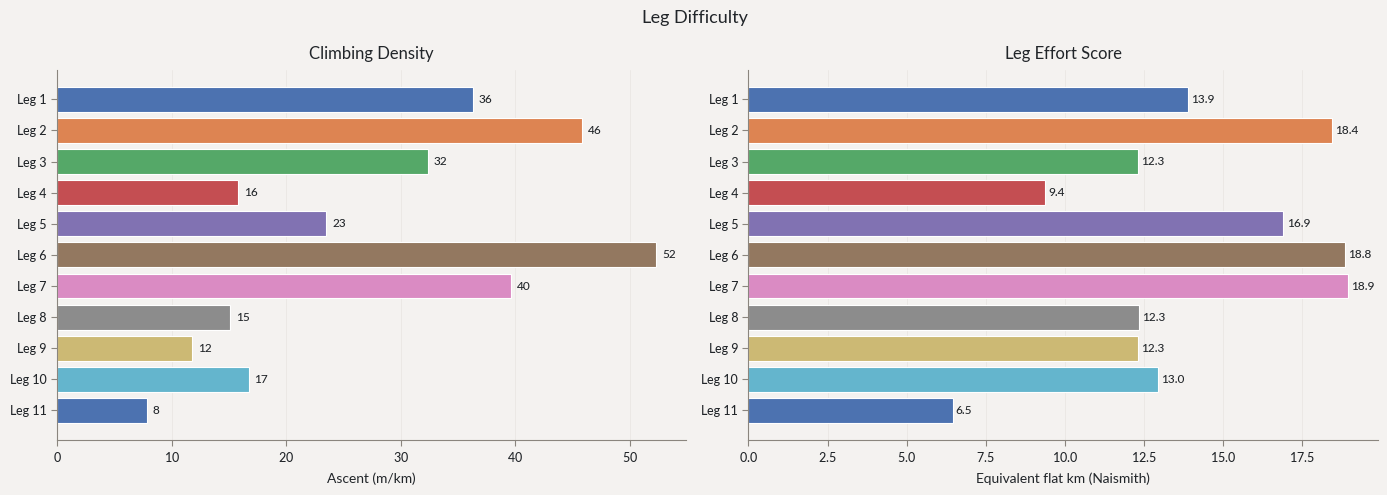

In [14]:
legs_df['Climbing density (m/km)'] = legs_df['Ascent (m)'] / legs_df['Distance (km)']
legs_df['Effort (eq. km)']         = legs_df['Naismith (h)'] * FLAT_SPEED_KMH

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
leg_labels_r = ['Leg ' + str(int(r['Leg'])) for _, r in legs_df.iterrows()][::-1]
colors_r     = [LEG_COLORS[i % len(LEG_COLORS)] for i in range(n_legs)][::-1]

ax1.barh(leg_labels_r, legs_df['Climbing density (m/km)'].values[::-1],
         color=colors_r, edgecolor='white')
for i, v in enumerate(legs_df['Climbing density (m/km)'].values[::-1]):
    ax1.text(v + 0.5, i, f'{v:.0f}', va='center', fontsize=8.5)
ax1.set_xlabel('Ascent (m/km)')
ax1.set_title('Climbing Density')
ax1.grid(axis='x', alpha=0.35)

ax2.barh(leg_labels_r, legs_df['Effort (eq. km)'].values[::-1],
         color=colors_r, edgecolor='white')
for i, v in enumerate(legs_df['Effort (eq. km)'].values[::-1]):
    ax2.text(v + 0.1, i, f'{v:.1f}', va='center', fontsize=8.5)
ax2.set_xlabel('Equivalent flat km (Naismith)')
ax2.set_title('Leg Effort Score')
ax2.grid(axis='x', alpha=0.35)

fig.suptitle('Leg Difficulty', fontsize=13)
plt.tight_layout()
plt.show()

## 13. Cumulative ascent profile

The bottom panel shows how the total climbing accumulates over the route. A steep section in the cumulative curve means a lot of ascent concentrated in a short distance; a flat section is a descent or flat traverse.

/tmp/ipykernel_25150/3716361666.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_25150/3716361666.py:31: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


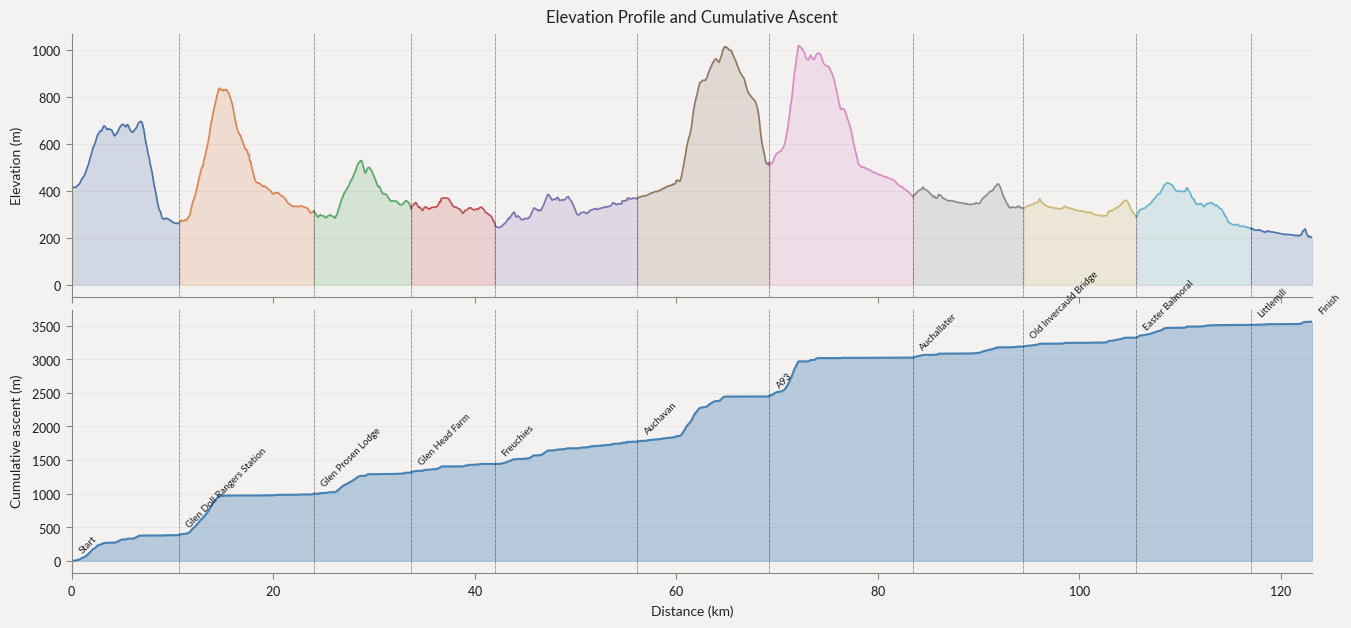

In [15]:
ele_gain     = np.diff(eles)
cum_ascent_m = np.concatenate([[0], np.cumsum(np.where(ele_gain > 0, ele_gain, 0))])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 7), sharex=True,
                                gridspec_kw={'hspace': 0.05})

for k, leg in legs_df.iterrows():
    i0, i1 = int(leg['i0']), int(leg['i1'])
    c = LEG_COLORS[k % len(LEG_COLORS)]
    ax1.fill_between(cum_dist_km[i0:i1+1], eles[i0:i1+1], alpha=0.2, color=c)
    ax1.plot(cum_dist_km[i0:i1+1], eles[i0:i1+1], color=c, lw=1.2)

ax2.fill_between(cum_dist_km, cum_ascent_m, color='steelblue', alpha=0.35)
ax2.plot(cum_dist_km, cum_ascent_m, color='steelblue', lw=1.5)

for wpt in waypoints:
    ax1.axvline(wpt['dist_km'], color='black', lw=0.6, ls='--', alpha=0.4)
    ax2.axvline(wpt['dist_km'], color='black', lw=0.6, ls='--', alpha=0.4)
    ca = float(np.interp(wpt['dist_km'], cum_dist_km, cum_ascent_m))
    ax2.annotate(wpt['name'], xy=(wpt['dist_km'], ca),
                 xytext=(4, 4), textcoords='offset points',
                 fontsize=7, rotation=45, va='bottom')

ax1.set_ylabel('Elevation (m)')
ax1.set_title('Elevation Profile and Cumulative Ascent')
ax1.grid(axis='y', alpha=0.4)
ax2.set_ylabel('Cumulative ascent (m)')
ax2.set_xlabel('Distance (km)')
ax2.set_xlim(0, cum_dist_km[-1])
ax2.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

## 14. Gradient distribution

Histogram and CDF of gradient magnitudes for the uphill and downhill sections (>0.5% threshold to exclude near-flat noise). The CDF makes it easy to read off the median and 90th-percentile gradient.

/tmp/ipykernel_25150/3439222638.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


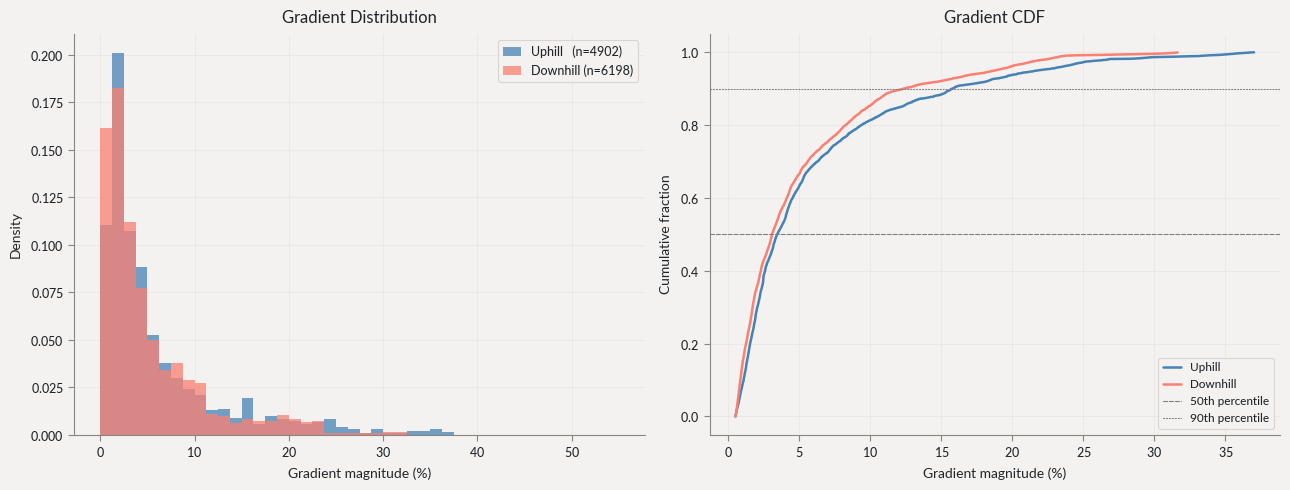

In [16]:
# grad was computed on d_uniform (10 m spacing) in the gradient cell above
uphill_g   =  grad[grad >  0.5]
downhill_g = -grad[grad < -0.5]   # flip sign so both are positive

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

bins = np.linspace(0, 55, 45)
ax1.hist(uphill_g,   bins=bins, alpha=0.75, color='steelblue',
         label=f'Uphill   (n={len(uphill_g)})', density=True)
ax1.hist(downhill_g, bins=bins, alpha=0.75, color='salmon',
         label=f'Downhill (n={len(downhill_g)})', density=True)
ax1.set_xlabel('Gradient magnitude (%)')
ax1.set_ylabel('Density')
ax1.set_title('Gradient Distribution')
ax1.legend()
ax1.grid(alpha=0.35)

for arr, color, label in [(uphill_g, 'steelblue', 'Uphill'), (downhill_g, 'salmon', 'Downhill')]:
    s = np.sort(arr)
    ax2.plot(s, np.linspace(0, 1, len(s)), color=color, lw=1.8, label=label)
for pct, ls in [(50, '--'), (90, ':')]:
    ax2.axhline(pct / 100, color='gray', lw=0.8, ls=ls, label=f'{pct}th percentile')
ax2.set_xlabel('Gradient magnitude (%)')
ax2.set_ylabel('Cumulative fraction')
ax2.set_title('Gradient CDF')
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.35)

plt.tight_layout()
plt.show()

## 15. Bearing / direction profile

Which way are you heading at each point on the route? The line plot shows the smoothed compass bearing vs distance; the rose diagram shows the overall distribution of travel directions.

/tmp/ipykernel_25150/2231830850.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_polar.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
/tmp/ipykernel_25150/2231830850.py:45: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


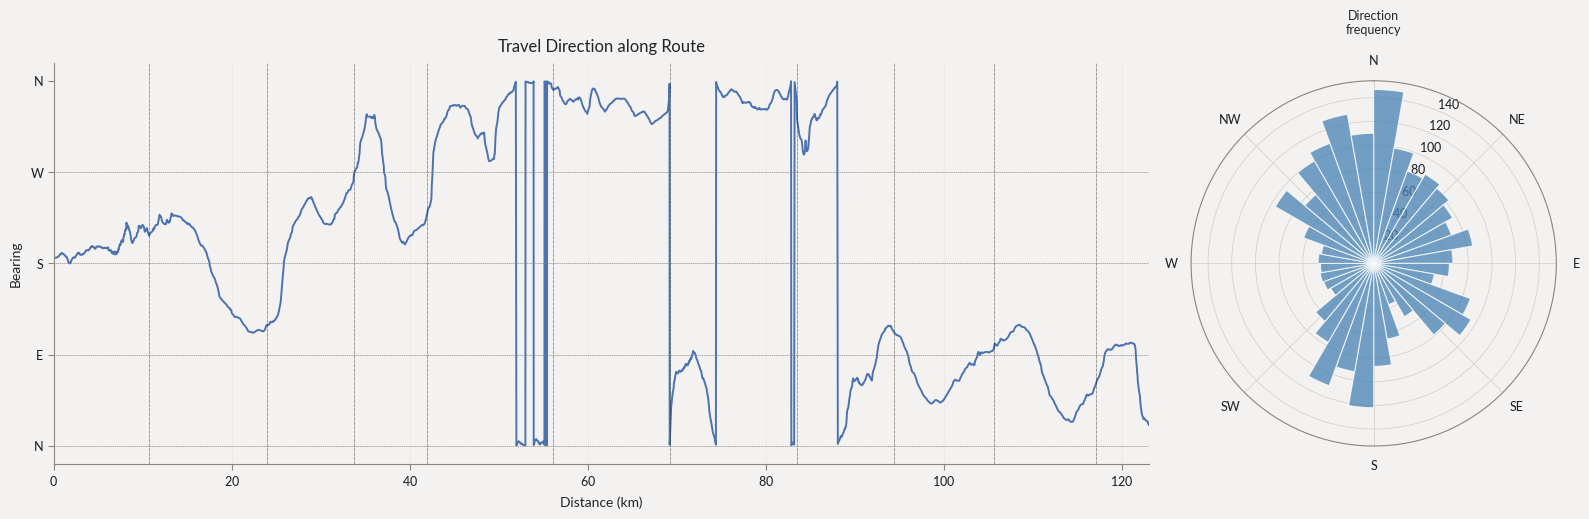

In [17]:
from scipy.ndimage import uniform_filter1d

# Bearing between consecutive track points
dlon_r = np.radians(np.diff(lons))
lat1_r, lat2_r = np.radians(lats[:-1]), np.radians(lats[1:])
bx_raw = np.sin(dlon_r) * np.cos(lat2_r)
by_raw = np.cos(lat1_r) * np.sin(lat2_r) - np.sin(lat1_r) * np.cos(lat2_r) * np.cos(dlon_r)
bearings_raw = (np.degrees(np.arctan2(bx_raw, by_raw)) + 360) % 360

# Smooth via unit-vector mean to handle circular wraparound
W = 80
bx_s = uniform_filter1d(np.sin(np.radians(bearings_raw)), W)
by_s = uniform_filter1d(np.cos(np.radians(bearings_raw)), W)
bearing_smooth = (np.degrees(np.arctan2(bx_s, by_s)) + 360) % 360
mid_dist = (cum_dist_km[:-1] + cum_dist_km[1:]) / 2

fig = plt.figure(figsize=(16, 5))
gs  = fig.add_gridspec(1, 2, width_ratios=[3, 1])
ax_line  = fig.add_subplot(gs[0, 0])
ax_polar = fig.add_subplot(gs[0, 1], projection='polar')

ax_line.plot(mid_dist, bearing_smooth, color='#4C72B0', lw=1.4)
for wpt in waypoints:
    ax_line.axvline(wpt['dist_km'], color='black', lw=0.6, ls='--', alpha=0.4)
for angle in [0, 90, 180, 270]:
    ax_line.axhline(angle, color='gray', lw=0.5, ls=':')
ax_line.set_yticks([0, 90, 180, 270, 360])
ax_line.set_yticklabels(['N', 'E', 'S', 'W', 'N'])
ax_line.set_xlim(0, cum_dist_km[-1])
ax_line.set_xlabel('Distance (km)')
ax_line.set_ylabel('Bearing')
ax_line.set_title('Travel Direction along Route')
ax_line.grid(axis='x', alpha=0.3)

bin_edges   = np.linspace(0, 2 * np.pi, 37)
counts, _   = np.histogram(np.radians(bearings_raw), bins=bin_edges)
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2
ax_polar.bar(bin_centres, counts, width=np.diff(bin_edges)[0],
             color='steelblue', alpha=0.75, edgecolor='white')
ax_polar.set_theta_zero_location('N')
ax_polar.set_theta_direction(-1)
ax_polar.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
ax_polar.set_title('Direction\nfrequency', fontsize=9, pad=15)

plt.tight_layout()
plt.show()

## 16. Out-and-back elevation symmetry

If the route doubled back on itself, elevation at distance *d* would equal elevation at (*total* − *d*) — all points would lie on the red diagonal. Scatter away from it reveals how different the terrain is in each direction. Colour shows how far along the route each point is.

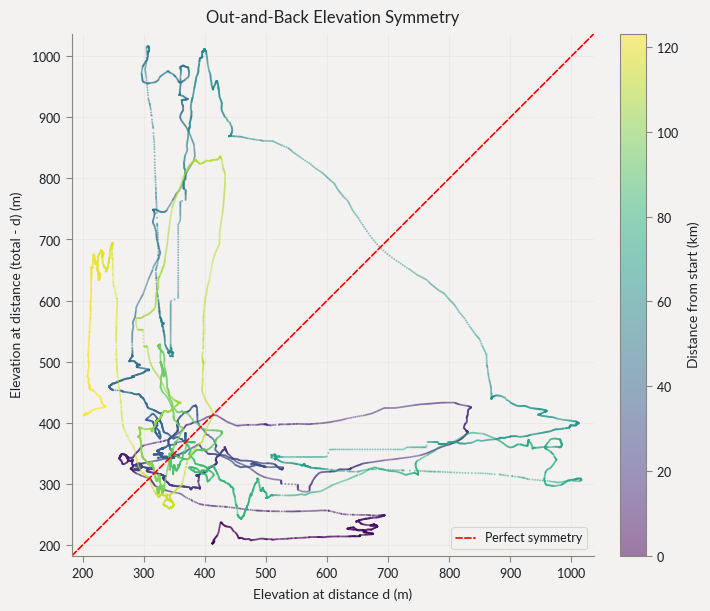

In [19]:
d_mirror = total_dist_km - d_uniform
e_mirror = np.interp(d_mirror, d_uniform, e_uniform)

lo = min(e_uniform.min(), e_mirror.min()) - 20
hi = max(e_uniform.max(), e_mirror.max()) + 20

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(e_uniform, e_mirror, c=d_uniform, cmap='viridis', s=2, alpha=0.5)
plt.colorbar(sc, ax=ax, label='Distance from start (km)')
ax.plot([lo, hi], [lo, hi], 'r--', lw=1.2, label='Perfect symmetry')
ax.set_xlabel('Elevation at distance d (m)')
ax.set_ylabel('Elevation at distance (total - d) (m)')
ax.set_title('Out-and-Back Elevation Symmetry')
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect('equal')
ax.legend()
ax.grid(alpha=0.3)
#plt.tight_layout()
plt.show()

## 17. Net elevation balance per leg

Which legs are net climbers and which are net descenders? This strips out the up/down noise and shows the net change from start to end of each leg.

/tmp/ipykernel_25150/699834168.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


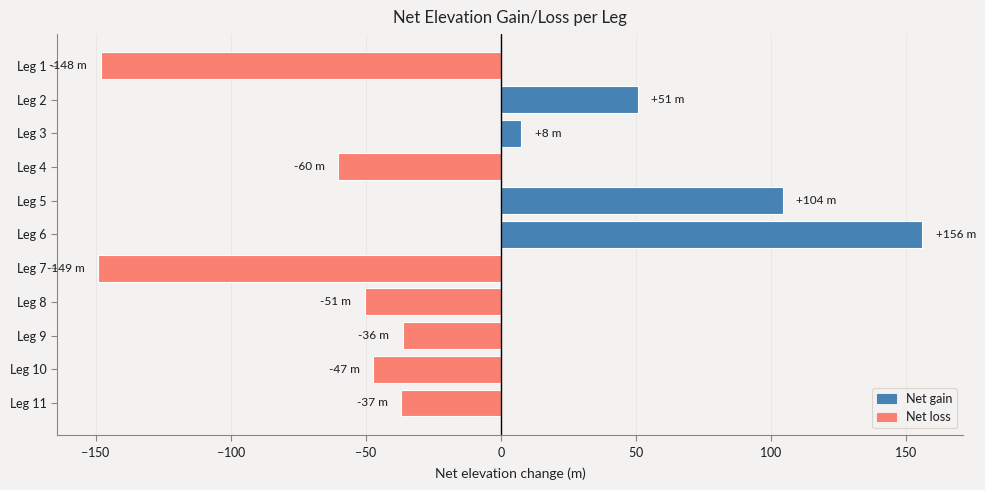

In [20]:
legs_df['Net elev. (m)'] = legs_df['End elev (m)'] - legs_df['Start elev (m)']

fig, ax = plt.subplots(figsize=(10, 5))
net_vals   = legs_df['Net elev. (m)'].values[::-1]
leg_labels = ['Leg ' + str(int(r['Leg'])) for _, r in legs_df.iterrows()][::-1]
bar_colors = ['steelblue' if v >= 0 else 'salmon' for v in net_vals]

bars = ax.barh(leg_labels, net_vals, color=bar_colors, edgecolor='white')
ax.axvline(0, color='black', lw=1)
for bar, v in zip(bars, net_vals):
    ha = 'left' if v >= 0 else 'right'
    ax.text(v + (5 if v >= 0 else -5), bar.get_y() + bar.get_height() / 2,
            f'{v:+.0f} m', va='center', ha=ha, fontsize=8.5)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='steelblue', label='Net gain'),
                   Patch(color='salmon',    label='Net loss')], loc='lower right')
ax.set_xlabel('Net elevation change (m)')
ax.set_title('Net Elevation Gain/Loss per Leg')
ax.grid(axis='x', alpha=0.4)
plt.tight_layout()
plt.show()